# Milestone M3 — Systematic Data Profiling Notebook (`m3_profile.ipynb`)

**Project:** Austin Animal Center — Shelter Intakes & Outcomes  
**Team:** Osman Kalkan (`230717048`), Irmak Köse (`230717027`), Ferdi Derebaşı (`230717056`)  
**Scope:** Systematic inspection of the Milestone M2 normalized database (`data/austin_animals.db`) across all six problem families defined in the M3 specification before writing any cleaning code:
1. **Family 1 — Missing values & mechanisms (MCAR / MAR / MNAR)**
2. **Family 2 — Invalid (impossible) values**
3. **Family 3 — Unusual (extreme but genuine) values**
4. **Family 4 — Failures across rows or fields (life stage, multi-stay sequences, clinical conflicts)**
5. **Family 5 — Text, categories, and units (`repr()` inspection & mapping discovery)**
6. **Family 6 — Identity & cross-key duplicate check**

In [1]:
import sqlite3
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 60)
pd.set_option("display.width", 120)

DB_PATH = Path("../data/austin_animals.db") if Path("../data/austin_animals.db").exists() else Path("data/austin_animals.db")
conn = sqlite3.connect(DB_PATH)
print(f"Connected to SQLite database: {DB_PATH.resolve()}")

Connected to SQLite database: C:\Users\Ferdi\.gemini\antigravity\brain\ab8731ba-3aef-4831-a564-62827942f0c6\scratch\m3dev\data\austin_animals.db


## 1. Baseline M2 Table Counts, Coverage, and Records-per-Entity Distribution

First, we inspect the row counts of all four M2 tables (`animals`, `intakes`, `outcomes`, `quarantine`), verify date ranges, and inspect how many intake and outcome records exist per `animal_key`.

In [2]:
overview_df = pd.read_sql_query(
    """
    SELECT 'animals'    AS table_name, COUNT(*) AS row_count, MIN(date_of_birth) AS min_date, MAX(date_of_birth) AS max_date FROM animals
    UNION ALL
    SELECT 'intakes'    AS table_name, COUNT(*) AS row_count, MIN(intake_at)     AS min_date, MAX(intake_at)     AS max_date FROM intakes
    UNION ALL
    SELECT 'outcomes'   AS table_name, COUNT(*) AS row_count, MIN(outcome_at)    AS min_date, MAX(outcome_at)    AS max_date FROM outcomes
    UNION ALL
    SELECT 'quarantine' AS table_name, COUNT(*) AS row_count, MIN(retrieved_at)  AS min_date, MAX(retrieved_at)  AS max_date FROM quarantine
    """,
    conn,
)
display(overview_df)

entity_dist = pd.read_sql_query(
    """
    WITH counts AS (
        SELECT
            a.animal_key,
            (SELECT COUNT(*) FROM intakes i WHERE i.animal_key = a.animal_key) AS n_intakes,
            (SELECT COUNT(*) FROM outcomes o WHERE o.animal_key = a.animal_key) AS n_outcomes
        FROM animals a
    )
    SELECT n_intakes, n_outcomes, COUNT(*) AS n_animals
    FROM counts
    GROUP BY n_intakes, n_outcomes
    ORDER BY n_animals DESC
    """,
    conn,
)
print("Distribution of (n_intakes, n_outcomes) per animal entity:")
display(entity_dist)

,table_name,row_count,min_date,max_date
0,animals,17696,2004-04-29,2026-09-28
1,intakes,18428,2025-05-05T01:45:00Z,2026-10-08T20:37:00Z
2,outcomes,17299,2025-05-05T15:08:00Z,2026-10-08T19:55:52Z
3,quarantine,1088,2026-10-08T21:33:39Z,2026-10-08T21:33:39Z


Distribution of (n_intakes, n_outcomes) per animal entity:


,n_intakes,n_outcomes,n_animals
0,1,1,15916
1,1,0,1092
2,2,2,502
3,2,1,73
4,3,3,44
5,1,2,40
6,4,4,9
7,3,2,5
8,1,3,4
9,5,5,4


## 2. Family 1 — Missing Values, Disguised Sentinels, and Missingness Mechanisms

We check every column for both SQL `NULL`s and disguised missingness (`'Unknown'`, `'unknown'`, `'No Name'`, `'*'`, or numeric IDs entered in name fields). We then test whether missingness depends on species (`animal_type`), intake channel (`intake_type`), or intake month to classify each column as **MCAR**, **MAR**, or **MNAR**.

In [3]:
missing_summary = pd.read_sql_query(
    """
    SELECT 'animals.date_of_birth' AS column_name,
           COUNT(*) AS total_rows,
           SUM(CASE WHEN date_of_birth IS NULL THEN 1 ELSE 0 END) AS sql_nulls,
           0 AS disguised_sentinels
    FROM animals
    UNION ALL
    SELECT 'animals.sex',
           COUNT(*),
           SUM(CASE WHEN sex IS NULL THEN 1 ELSE 0 END),
           SUM(CASE WHEN lower(COALESCE(sex, '')) = 'unknown' THEN 1 ELSE 0 END)
    FROM animals
    UNION ALL
    SELECT 'animals.primary_color',
           COUNT(*),
           SUM(CASE WHEN primary_color IS NULL THEN 1 ELSE 0 END),
           SUM(CASE WHEN lower(COALESCE(primary_color, '')) = 'unknown' THEN 1 ELSE 0 END)
    FROM animals
    UNION ALL
    SELECT 'animals.secondary_color',
           COUNT(*),
           SUM(CASE WHEN secondary_color IS NULL THEN 1 ELSE 0 END),
           SUM(CASE WHEN lower(COALESCE(secondary_color, '')) = 'unknown' THEN 1 ELSE 0 END)
    FROM animals
    UNION ALL
    SELECT 'intakes.name_at_intake',
           COUNT(*),
           SUM(CASE WHEN name_at_intake IS NULL THEN 1 ELSE 0 END),
           SUM(CASE WHEN lower(COALESCE(name_at_intake, '')) IN ('unknown','no name','*','kitten','puppy','cat','dog','bat','baby')
                      OR COALESCE(name_at_intake, '') GLOB '[0-9]*' THEN 1 ELSE 0 END)
    FROM intakes
    UNION ALL
    SELECT 'intakes.intake_health_condition',
           COUNT(*),
           SUM(CASE WHEN intake_health_condition IS NULL THEN 1 ELSE 0 END),
           0
    FROM intakes
    UNION ALL
    SELECT 'intakes.found_zip',
           COUNT(*),
           SUM(CASE WHEN found_zip IS NULL THEN 1 ELSE 0 END),
           0
    FROM intakes
    UNION ALL
    SELECT 'outcomes.name',
           COUNT(*),
           SUM(CASE WHEN name IS NULL THEN 1 ELSE 0 END),
           SUM(CASE WHEN lower(COALESCE(name, '')) IN ('unknown','no name','*','kitten','puppy','cat','dog','bat','baby')
                      OR COALESCE(name, '') GLOB '[0-9]*' THEN 1 ELSE 0 END)
    FROM outcomes
    UNION ALL
    SELECT 'outcomes.spayed_neutered',
           COUNT(*),
           SUM(CASE WHEN spayed_neutered IS NULL THEN 1 ELSE 0 END),
           SUM(CASE WHEN lower(COALESCE(spayed_neutered, '')) = 'unknown' THEN 1 ELSE 0 END)
    FROM outcomes
    UNION ALL
    SELECT 'outcomes.euthanasia_reason (Euthanized only)',
           COUNT(*),
           SUM(CASE WHEN euthanasia_reason IS NULL THEN 1 ELSE 0 END),
           0
    FROM outcomes
    WHERE outcome_status LIKE 'Euthanized%'
    """,
    conn,
)
missing_summary["total_missing"] = missing_summary["sql_nulls"] + missing_summary["disguised_sentinels"]
missing_summary["missing_pct"] = (100.0 * missing_summary["total_missing"] / missing_summary["total_rows"]).round(2)
display(missing_summary)

,column_name,total_rows,sql_nulls,disguised_sentinels,total_missing,missing_pct
0,animals.date_of_birth,17696,1561,0,1561,8.82
1,animals.sex,17696,21,2782,2803,15.84
2,animals.primary_color,17696,0,21,21,0.12
3,animals.secondary_color,17696,8473,0,8473,47.88
4,intakes.name_at_intake,18428,7553,263,7816,42.41
5,intakes.intake_health_condition,18428,15367,0,15367,83.39
6,intakes.found_zip,18428,2447,0,2447,13.28
7,outcomes.name,17299,7235,246,7481,43.25
8,outcomes.spayed_neutered,17299,15,3112,3127,18.08
9,outcomes.euthanasia_reason (Euthanized only),1076,20,0,20,1.86


In [4]:
# Test MAR / MNAR by conditioning missingness on raw animal_type, intake_type, and intake month
mar_by_species = pd.read_sql_query(
    """
    SELECT
        animal_type,
        COUNT(*) AS n_animals,
        ROUND(100.0 * SUM(CASE WHEN date_of_birth IS NULL THEN 1 ELSE 0 END) / COUNT(*), 1) AS dob_null_pct,
        ROUND(100.0 * SUM(CASE WHEN sex IS NULL OR lower(sex) = 'unknown' THEN 1 ELSE 0 END) / COUNT(*), 1) AS sex_missing_pct
    FROM animals
    GROUP BY animal_type
    HAVING COUNT(*) >= 15
    ORDER BY n_animals DESC
    """,
    conn,
)
print("Missingness conditioned on raw animal_type (demonstrating MAR in Wildlife/Mammal and Juvenile groups):")
display(mar_by_species)

mar_by_intake = pd.read_sql_query(
    """
    SELECT
        i.intake_type,
        COUNT(*) AS n_intakes,
        ROUND(100.0 * SUM(CASE WHEN a.date_of_birth IS NULL THEN 1 ELSE 0 END) / COUNT(*), 1) AS dob_null_pct,
        ROUND(100.0 * SUM(CASE WHEN i.name_at_intake IS NULL THEN 1 ELSE 0 END) / COUNT(*), 1) AS name_null_pct,
        ROUND(100.0 * SUM(CASE WHEN i.intake_health_condition IS NULL THEN 1 ELSE 0 END) / COUNT(*), 1) AS health_null_pct,
        ROUND(100.0 * SUM(CASE WHEN i.found_zip IS NULL THEN 1 ELSE 0 END) / COUNT(*), 1) AS zip_null_pct
    FROM intakes i
    JOIN animals a ON a.animal_key = i.animal_key
    GROUP BY i.intake_type
    HAVING COUNT(*) >= 30
    ORDER BY n_intakes DESC
    """,
    conn,
)
print("Missingness conditioned on raw intake_type (Stray/ACO vs Owner Surrender/Returns):")
display(mar_by_intake)

mar_by_month = pd.read_sql_query(
    """
    SELECT
        substr(i.intake_at, 1, 7) AS intake_month,
        COUNT(*) AS n_intakes,
        ROUND(100.0 * SUM(CASE WHEN a.date_of_birth IS NULL THEN 1 ELSE 0 END) / COUNT(*), 1) AS dob_null_pct,
        ROUND(100.0 * SUM(CASE WHEN i.intake_health_condition IS NULL THEN 1 ELSE 0 END) / COUNT(*), 1) AS health_null_pct
    FROM intakes i
    JOIN animals a ON a.animal_key = i.animal_key
    WHERE i.intake_at >= '2025-10-01'
    GROUP BY intake_month
    ORDER BY intake_month
    """,
    conn,
)
print("Missingness over time (monthly from 2025-10 to 2026-10):")
display(mar_by_month)

Missingness conditioned on raw animal_type (demonstrating MAR in Wildlife/Mammal and Juvenile groups):


,animal_type,n_animals,dob_null_pct,sex_missing_pct
0,Cat,8426,2.9,11.1
1,Dog,6019,3.0,4.3
2,Kitten,1788,16.1,30.9
3,Mammal,832,75.7,98.0
4,Puppy,338,19.5,26.9
5,Rabbit,72,26.4,5.6
6,Guinea Pig,48,25.0,33.3
7,Reptile,35,54.3,82.9
8,Bird (wildlife),32,65.6,100.0
9,Bird,27,66.7,74.1


Missingness conditioned on raw intake_type (Stray/ACO vs Owner Surrender/Returns):


,intake_type,n_intakes,dob_null_pct,name_null_pct,health_null_pct,zip_null_pct
0,Stray,5870,4.6,48.0,91.4,1.1
1,ACO - Impound,5123,19.8,41.2,68.6,21.0
2,Community Animal - Program,4167,3.3,51.2,90.7,2.1
3,Owner Surrender,1701,3.4,3.3,88.9,50.6
4,Returns,484,0.4,1.9,78.3,17.8
5,Agency,342,5.0,15.8,90.1,0.6
6,Ambulance,316,13.0,63.6,50.0,11.4
7,ACO - Owner Surrender,179,2.8,20.1,69.3,72.6
8,Abandoned,94,1.1,45.7,87.2,18.1
9,Shelter Offspring,85,18.8,61.2,100.0,64.7


Missingness over time (monthly from 2025-10 to 2026-10):


,intake_month,n_intakes,dob_null_pct,health_null_pct
0,2025-10,1067,6.9,83.4
1,2025-11,727,7.2,86.0
2,2025-12,651,7.4,78.6
3,2026-01,731,7.8,76.9
4,2026-02,820,8.5,81.2
5,2026-03,947,14.6,76.7
6,2026-04,1095,9.7,81.2
7,2026-05,1370,10.5,79.4
8,2026-06,1543,8.4,82.8
9,2026-07,1089,10.0,82.1


## 3. Family 2 — Invalid (Impossible) Values

We check for three physical or geographic impossibilities:
1. **`animals.date_of_birth > first_intake_date`**: Animals recorded as born *after* they entered the shelter (69 animals, 1 to 56 days after intake).
2. **`intakes.found_zip` outside Texas prefixes (`73`–`79`)**: 109 rows where M2's 5-digit regex `\b(\d{5})\b` matched a 5-digit street house number (`10810`, `12209`, `12320`, etc.) when the raw address omitted the postal code (e.g., `'12209 Loma Vista Circle, TX, United States'`).
3. **`outcomes.days_in_shelter < 0` or `outcome_at < intake_at`**: 1 record (`animal_id = '22385'`, DOA on `2026-03-05`) where `outcome_at` (`22:16Z`) is 82 minutes earlier than `intake_at` (`23:38Z`).

In [5]:
# 1. Animals with date_of_birth after their first intake date
dob_after_intake = pd.read_sql_query(
    """
    SELECT
        a.animal_key,
        a.animal_id,
        a.animal_type,
        a.date_of_birth,
        MIN(substr(i.intake_at, 1, 10)) AS first_intake_date,
        CAST(julianday(MIN(substr(i.intake_at, 1, 10))) - julianday(a.date_of_birth) AS INTEGER) AS age_days_at_intake
    FROM animals a
    JOIN intakes i ON i.animal_key = a.animal_key
    WHERE a.date_of_birth IS NOT NULL
    GROUP BY a.animal_key
    HAVING a.date_of_birth > first_intake_date
    ORDER BY age_days_at_intake ASC
    """,
    conn,
)
print(f"Animals with date_of_birth > first_intake_date: {len(dob_after_intake)} rows")
display(dob_after_intake.head(10))

# 2. Invalid found_zip tokens (5-digit street house numbers captured when address lacked a ZIP code)
zip_df = pd.read_sql_query(
    """
    SELECT
        found_zip,
        COUNT(*) AS row_count,
        CASE
            WHEN substr(found_zip, 1, 3) IN ('786', '787') THEN 'valid_austin_metro'
            WHEN substr(found_zip, 1, 2) IN ('73', '75', '76', '77', '78', '79') THEN 'unusual_texas_outside_austin'
            ELSE 'invalid_house_number_as_zip'
        END AS zip_classification
    FROM intakes
    WHERE found_zip IS NOT NULL
    GROUP BY found_zip
    ORDER BY zip_classification, row_count DESC
    """,
    conn,
)
print("Summary of non-null found_zip values by classification:")
display(zip_df.groupby("zip_classification")["row_count"].agg(distinct_codes="count", total_rows="sum"))
print("Top invalid house-number tokens captured as found_zip:")
display(zip_df[zip_df["zip_classification"] == "invalid_house_number_as_zip"].head(12))

# 3. Outcome timestamp preceding intake timestamp
neg_outcomes = pd.read_sql_query(
    """
    SELECT
        o.animal_key,
        a.animal_id,
        a.animal_type,
        o.intake_at,
        o.outcome_at,
        o.outcome_status,
        o.days_in_shelter,
        ROUND((julianday(o.outcome_at) - julianday(o.intake_at)) * 24.0 * 60.0, 1) AS stay_minutes
    FROM outcomes o
    JOIN animals a ON a.animal_key = o.animal_key
    WHERE o.outcome_at < o.intake_at OR o.days_in_shelter < 0
    """,
    conn,
)
print(f"Outcomes with outcome_at < intake_at: {len(neg_outcomes)} row(s)")
display(neg_outcomes)

Animals with date_of_birth > first_intake_date: 69 rows


,animal_key,animal_id,animal_type,date_of_birth,first_intake_date,age_days_at_intake
0,12306,26535,Kitten,2026-07-18,2026-05-23,-56
1,3393,12677,Cat,2025-08-22,2025-07-24,-29
2,3394,12678,Cat,2025-08-22,2025-07-24,-29
3,13396,29732,Kitten,2026-07-02,2026-06-15,-17
4,13117,29082,Kitten,2026-06-21,2026-06-09,-12
5,13118,29083,Kitten,2026-06-21,2026-06-09,-12
6,13119,29084,Kitten,2026-06-21,2026-06-09,-12
7,3513,12874,Cat,2025-08-06,2025-07-28,-9
8,3514,12875,Cat,2025-08-06,2025-07-28,-9
9,926,8903,Kitten,2025-06-02,2025-05-25,-8


Summary of non-null found_zip values by classification:


,distinct_codes,total_rows
zip_classification,,
invalid_house_number_as_zip,48,109
unusual_texas_outside_austin,9,15
valid_austin_metro,82,15857


Top invalid house-number tokens captured as found_zip:


,found_zip,row_count,zip_classification
0,10810,13,invalid_house_number_as_zip
1,12320,8,invalid_house_number_as_zip
2,12209,6,invalid_house_number_as_zip
3,16100,6,invalid_house_number_as_zip
4,10714,5,invalid_house_number_as_zip
5,11708,5,invalid_house_number_as_zip
6,14212,4,invalid_house_number_as_zip
7,14602,4,invalid_house_number_as_zip
8,11717,3,invalid_house_number_as_zip
9,12015,3,invalid_house_number_as_zip


Outcomes with outcome_at < intake_at: 1 row(s)


,animal_key,animal_id,animal_type,intake_at,outcome_at,outcome_status,days_in_shelter,stay_minutes
0,9568,22385,Dog,2026-03-05T23:38:00Z,2026-03-05T22:16:00Z,DOA,0,-82.0


## 4. Family 3 — Unusual (Extreme but Genuine) Values & Distribution Quantiles

Because shelter length of stay (`days_in_shelter`) is heavily right-skewed, a Gaussian mean ± 3 SD rule is inappropriate. Instead, we inspect the median, quartiles (`Q1`, `Q3`), `IQR`, `MAD`, `p95`, `p99`, and `max` within each canonical species group and apply Tukey's outer fence (`Q3 + 3.0 * IQR`) to flag extreme long-stay cases (`unusual_high_stay`) while **keeping** every genuine observation.

,canonical_species,n_outcomes,min,Q1,median,MAD,Q3,IQR,p95,p99,max,outer_fence_Q3_3IQR,n_unusual_high_stay
1,Cat,10036,0,4.0,7.0,6.0,25.0,21.0,70.0,127.6,358,88.0,278
2,Dog,6303,0,4.0,9.0,8.0,31.0,27.0,124.9,245.0,484,112.0,365
7,Wildlife,694,0,0.0,4.0,4.0,34.0,34.0,176.0,264.7,340,136.0,43
6,Small Mammal,140,0,5.8,14.0,10.5,41.0,35.2,74.2,116.4,141,146.8,0
0,Bird,80,0,1.0,5.0,5.0,22.0,21.0,78.5,108.2,109,85.0,4
5,Reptile,35,0,1.0,6.0,5.0,22.0,21.0,102.5,327.8,424,85.0,3
4,Other,6,5,5.0,5.5,0.5,7.5,2.5,16.2,18.5,19,96.0,0
3,Livestock,4,4,4.0,5.0,1.0,9.2,5.2,17.0,18.6,19,96.0,0


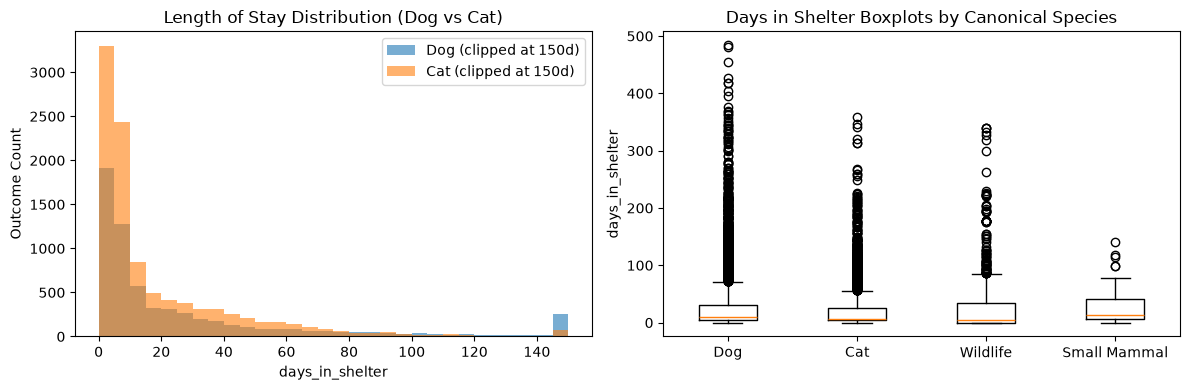

In [6]:
stays_df = pd.read_sql_query(
    """
    SELECT
        o.animal_key,
        a.animal_type AS raw_type,
        CASE
            WHEN a.animal_type IN ('Cat', 'Kitten') THEN 'Cat'
            WHEN a.animal_type IN ('Dog', 'Puppy') THEN 'Dog'
            WHEN a.animal_type IN ('Mammal', 'Marsupial') THEN 'Wildlife'
            WHEN a.animal_type IN ('Rabbit', 'Guinea Pig', 'Rodent', 'Ferret') THEN 'Small Mammal'
            WHEN a.animal_type IN ('Bird (wildlife)', 'Bird', 'Fowl') THEN 'Bird'
            WHEN a.animal_type IN ('Reptile', 'Reptile (Wildlife)') THEN 'Reptile'
            WHEN a.animal_type IN ('Goat', 'Sheep') THEN 'Livestock'
            ELSE 'Other'
        END AS canonical_species,
        o.days_in_shelter,
        (julianday(o.outcome_at) - julianday(o.intake_at)) AS exact_stay_days
    FROM outcomes o
    JOIN animals a ON a.animal_key = o.animal_key
    WHERE o.outcome_at >= o.intake_at
    """,
    conn,
)

stats_rows = []
for sp, grp in stays_df.groupby("canonical_species"):
    s = grp["days_in_shelter"].dropna()
    q1 = s.quantile(0.25)
    med = s.quantile(0.50)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    mad = (s - med).abs().median()
    fence = q3 + 3.0 * iqr if len(s) >= 30 else 96.0
    n_unusual = int((s > fence).sum())
    stats_rows.append({
        "canonical_species": sp,
        "n_outcomes": len(s),
        "min": int(s.min()),
        "Q1": round(q1, 1),
        "median": round(med, 1),
        "MAD": round(mad, 1),
        "Q3": round(q3, 1),
        "IQR": round(iqr, 1),
        "p95": round(s.quantile(0.95), 1),
        "p99": round(s.quantile(0.99), 1),
        "max": int(s.max()),
        "outer_fence_Q3_3IQR": round(fence, 1),
        "n_unusual_high_stay": n_unusual,
    })

stats_df = pd.DataFrame(stats_rows).sort_values("n_outcomes", ascending=False)
display(stats_df)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for sp, color in [("Dog", "#1f77b4"), ("Cat", "#ff7f0e")]:
    sub = stays_df[stays_df["canonical_species"] == sp]["days_in_shelter"]
    axes[0].hist(sub.clip(upper=150), bins=30, alpha=0.6, label=f"{sp} (clipped at 150d)", color=color)
axes[0].set_title("Length of Stay Distribution (Dog vs Cat)")
axes[0].set_xlabel("days_in_shelter")
axes[0].set_ylabel("Outcome Count")
axes[0].legend()

box_groups = [
    stays_df[stays_df["canonical_species"] == sp]["days_in_shelter"].values
    for sp in ["Dog", "Cat", "Wildlife", "Small Mammal"]
]
axes[1].boxplot(box_groups, tick_labels=["Dog", "Cat", "Wildlife", "Small Mammal"], showfliers=True)
axes[1].set_title("Days in Shelter Boxplots by Canonical Species")
axes[1].set_ylabel("days_in_shelter")
plt.tight_layout()
plt.show()

## 5. Family 4 — Failures Across Rows or Fields

We inspect four cross-field / cross-row failure modes:
1. **Life-stage vs age at intake**: Raw `animal_type` mixes species (`Cat`, `Dog`) with juvenile labels (`Kitten`, `Puppy`). Computing age at first intake (`first_intake_date - date_of_birth`) shows 3,070 rows raw-labelled `Cat`/`Dog` that were `< 56` days old (neonates/juveniles) at intake, plus 1 row raw-labelled `Kitten` (`animal_id = '36020'`) that was `732` days old (`> 365` days) at intake.
2. **Multiple outcomes linked to the same intake (`(animal_key, intake_at)`)**: 46 intake stays have 2–3 outcome rows (50 secondary exit rows total), caused by updated disposal timestamps on `DOA` records or revised adoption timestamps.
3. **Multi-stay sequence anomalies**: 1 intake (`animal_key = 13834`) occurs *before* the prior stay's outcome timestamp (`overlap_with_prior_stay`), and 12 intakes occur after a prior intake that has no recorded outcome (`reintake_after_open_stay`).
4. **Cross-field clinical conflicts**: 99 outcomes carry a non-null `euthanasia_reason` (`Suffering`, `Rabies Risk`, `Injured`) even though `outcome_status` is `DOA`, `Unassisted Death`, `Reclaimed`, or `Adopted`; and 1 outcome has `spayed_neutered = 'No'` despite `previously_spayed_neutered = 1` at intake.

In [7]:
# 1. Life-stage vs age at first intake
age_check = pd.read_sql_query(
    """
    WITH first_int AS (
        SELECT animal_key, MIN(substr(intake_at, 1, 10)) AS first_intake_date
        FROM intakes
        GROUP BY animal_key
    )
    SELECT
        a.animal_type AS raw_type,
        COUNT(*) AS total_with_valid_dob,
        SUM(CASE WHEN (julianday(f.first_intake_date) - julianday(a.date_of_birth)) < 56 THEN 1 ELSE 0 END) AS under_56d,
        SUM(CASE WHEN (julianday(f.first_intake_date) - julianday(a.date_of_birth)) <= 180 THEN 1 ELSE 0 END) AS under_180d,
        SUM(CASE WHEN (julianday(f.first_intake_date) - julianday(a.date_of_birth)) > 365 THEN 1 ELSE 0 END) AS over_365d
    FROM animals a
    JOIN first_int f ON f.animal_key = a.animal_key
    WHERE a.date_of_birth IS NOT NULL
      AND a.date_of_birth <= f.first_intake_date
      AND a.animal_type IN ('Cat', 'Kitten', 'Dog', 'Puppy')
    GROUP BY a.animal_type
    """,
    conn,
)
print("Age at first intake vs raw Cat/Kitten/Dog/Puppy label:")
display(age_check)

# 2. Multiple outcomes per (animal_key, intake_at) stay
dup_outcomes = pd.read_sql_query(
    """
    SELECT
        animal_key,
        intake_at,
        COUNT(*) AS n_outcomes_for_stay,
        GROUP_CONCAT(outcome_status || '@' || outcome_at, ' | ') AS outcome_chain
    FROM outcomes
    GROUP BY animal_key, intake_at
    HAVING COUNT(*) > 1
    ORDER BY n_outcomes_for_stay DESC, animal_key
    """,
    conn,
)
print(f"Intakes with multiple outcome rows: {len(dup_outcomes)} stays ({dup_outcomes['n_outcomes_for_stay'].sum() - len(dup_outcomes)} secondary exit rows)")
display(dup_outcomes.head(10))

# 3. Cross-field clinical conflicts on outcomes
clinical_conflicts = pd.read_sql_query(
    """
    SELECT
        outcome_status,
        euthanasia_reason,
        COUNT(*) AS row_count
    FROM outcomes
    WHERE euthanasia_reason IS NOT NULL
      AND outcome_status NOT LIKE 'Euthanized%'
    GROUP BY outcome_status, euthanasia_reason
    ORDER BY row_count DESC
    """,
    conn,
)
print("Outcomes with non-null euthanasia_reason but non-euthanasia outcome_status (99 rows total):")
display(clinical_conflicts)

Age at first intake vs raw Cat/Kitten/Dog/Puppy label:


,raw_type,total_with_valid_dob,under_56d,under_180d,over_365d
0,Cat,8141,2477,4376,2609
1,Dog,5835,593,1729,3147
2,Kitten,1480,1133,1479,1
3,Puppy,261,165,261,0


Intakes with multiple outcome rows: 46 stays (50 secondary exit rows)


,animal_key,intake_at,n_outcomes_for_stay,outcome_chain
0,4540,2025-08-28T11:51:00Z,3,DOA@2025-08-28T11:51:00Z | DOA@2025-08-30T16:0...
1,14454,2026-07-09T16:24:00Z,3,DOA@2026-07-09T16:24:00Z | DOA@2026-07-13T16:1...
2,14992,2026-07-26T12:23:00Z,3,DOA@2026-07-26T12:23:00Z | DOA@2026-08-01T21:4...
3,15520,2026-08-10T19:59:00Z,3,Transfer Out@2026-08-14T17:02:00Z | Transfer O...
4,135,2025-05-08T02:12:00Z,2,DOA@2025-05-08T02:12:00Z | DOA@2025-05-10T18:0...
5,1267,2025-06-02T10:16:00Z,2,DOA@2025-06-02T10:16:00Z | DOA@2025-07-03T20:1...
6,3533,2025-07-29T16:13:00Z,2,Adopted@2025-08-20T21:24:45Z | Adopted@2025-08...
7,3871,2025-08-06T17:03:00Z,2,DOA@2025-08-06T17:03:00Z | DOA@2025-10-22T13:4...
8,3872,2025-08-06T17:03:00Z,2,DOA@2025-08-06T17:03:00Z | DOA@2025-10-22T13:4...
9,3873,2025-08-06T17:03:00Z,2,DOA@2025-08-06T17:03:00Z | DOA@2025-10-22T13:4...


Outcomes with non-null euthanasia_reason but non-euthanasia outcome_status (99 rows total):


,outcome_status,euthanasia_reason,row_count
0,DOA,Suffering,19
1,Unassisted Death - In Transit,Rabies Risk,14
2,Unassisted Death,Rabies Risk,13
3,DOA,Rabies Risk,7
4,Reclaimed,Suffering,7
5,Reclaimed,Court Order,5
6,Unassisted Death,Suffering,5
7,Adopted,Suffering,3
8,Euthanasia - RTO,Court Order,3
9,Reclaimed,Aggression,3


## 6. Family 5 — Text, Categories, and Units (`repr()` Inspection)

We inspect distinct values of categorical and free-text columns using Python `repr()` to expose casing mismatches (`'Yes'` vs `'yes'`, `'Unknown'` vs `'unknown'`, `'Neonate'` vs `'NEONATAL'`, `'MED ATTN'` vs `'MEDICAL'`), shelter asterisk prefixes (`'*Fluffy'`), and hierarchical subtype slashes (`'Adopted / Foster'`, `'Transfer / Rescue Group'`).

In [8]:
for label, query_sql in [
    ("animals.animal_type", "SELECT animal_type, COUNT(*) AS n FROM animals GROUP BY animal_type ORDER BY n DESC"),
    ("animals.sex", "SELECT sex, COUNT(*) AS n FROM animals GROUP BY sex ORDER BY n DESC"),
    ("intakes.intake_type", "SELECT intake_type, COUNT(*) AS n FROM intakes GROUP BY intake_type ORDER BY n DESC"),
    ("intakes.intake_health_condition", "SELECT intake_health_condition, COUNT(*) AS n FROM intakes GROUP BY intake_health_condition ORDER BY n DESC"),
    ("outcomes.outcome_status", "SELECT outcome_status, COUNT(*) AS n FROM outcomes GROUP BY outcome_status ORDER BY n DESC"),
    ("outcomes.spayed_neutered", "SELECT spayed_neutered, COUNT(*) AS n FROM outcomes GROUP BY spayed_neutered ORDER BY n DESC"),
]:
    rows = conn.execute(query_sql).fetchall()
    print(f"=== {label} ({len(rows)} distinct values) ===")
    for val, n in rows:
        print(f"  {repr(val):<42} -> {n:>6}")
    print()

=== animals.animal_type (20 distinct values) ===
  'Cat'                                      ->   8426
  'Dog'                                      ->   6019
  'Kitten'                                   ->   1788
  'Mammal'                                   ->    832
  'Puppy'                                    ->    338
  'Rabbit'                                   ->     72
  'Guinea Pig'                               ->     48
  'Reptile'                                  ->     35
  'Bird (wildlife)'                          ->     32
  'Bird'                                     ->     27
  'Fowl'                                     ->     22
  'Rodent'                                   ->     18
  'Marsupial'                                ->     15
  'Reptile (Wildlife)'                       ->      9
  'Ferret'                                   ->      4
  'Crab/fish'                                ->      4
  'Goat'                                     ->      3
  'Sheep'       

## 7. Family 6 — Identity & Cross-Key Duplicate Inspection

Finally, we check whether the same real-world animal appears under more than one `animal_id` by grouping animals with identical `(lower(name_at_intake), date_of_birth, primary_breed, primary_color, sex)`. Out of 24 multi-ID groups, 21 share the exact same `intake_at` timestamp and sequential shelter IDs (littermates surrendered together under shared labels like `'Kitten'`, `'Unknown'`, `'Star'`, `'Siouxsie'`). Only 1 named pair (`'Oliver'`, `animal_id` `'25447'` and `'30349'`) is a plausible re-registration across separate months; without microchip identifiers, merging `animal_id` keys would be speculative, so `animal_id` is kept unmerged and documented.

In [9]:
identity_candidates = pd.read_sql_query(
    """
    SELECT
        lower(trim(i.name_at_intake)) AS norm_name,
        a.date_of_birth,
        a.primary_breed,
        a.primary_color,
        a.sex,
        COUNT(DISTINCT a.animal_id) AS n_distinct_ids,
        GROUP_CONCAT(DISTINCT a.animal_id) AS animal_ids,
        MIN(i.intake_at) AS min_intake_at,
        MAX(i.intake_at) AS max_intake_at
    FROM animals a
    JOIN intakes i ON i.animal_key = a.animal_key
    WHERE i.name_at_intake IS NOT NULL
      AND a.date_of_birth IS NOT NULL
    GROUP BY norm_name, a.date_of_birth, a.primary_breed, a.primary_color, a.sex
    HAVING COUNT(DISTINCT a.animal_id) > 1
    ORDER BY (MIN(i.intake_at) != MAX(i.intake_at)) DESC, n_distinct_ids DESC
    """,
    conn,
)
print(f"Multi-ID groups sharing (name, DOB, breed, color, sex): {len(identity_candidates)} groups")
display(identity_candidates.head(15))
conn.close()

Multi-ID groups sharing (name, DOB, breed, color, sex): 24 groups


,norm_name,date_of_birth,primary_breed,primary_color,sex,n_distinct_ids,animal_ids,min_intake_at,max_intake_at
0,oliver,2026-03-24,Domestic Shorthair,Orange Tabby,Male,2,"25447,30349",2026-05-05T18:53:00Z,2026-07-22T18:15:00Z
1,unknown,2024-09-12,Skunk - Striped,Black,Unknown,2,"32903,32911",2026-09-12T14:51:00Z,2026-09-12T15:23:00Z
2,unknown,2025-10-15,American Pit Bull Terrier,Grey,Male,2,"17482,17483",2025-10-29T18:32:00Z,2025-10-29T18:38:00Z
3,unknown,2026-05-12,Domestic Shorthair,Black,Male,2,"28030,28035",2026-06-12T03:29:00Z,2026-06-12T13:47:00Z
4,unknown,2026-08-22,Domestic Shorthair,Black,Unknown,6,"32279,32280,32282,32283,32284,32285",2026-08-29T14:13:00Z,2026-08-29T14:13:00Z
5,kittens,2026-05-06,Domestic Shorthair,Black,Unknown,5,"26714,26715,26716,26717,26718",2026-05-27T16:21:00Z,2026-05-27T16:21:00Z
6,star,2024-09-19,American Pit Bull Terrier,Blue,Unknown,5,"33588,33589,33580,33581,33582",2026-09-18T18:07:00Z,2026-09-18T18:07:00Z
7,unknown,2026-08-14,Domestic Shorthair,Grey,Unknown,4,"32210,32211,32212,32213",2026-08-28T13:53:00Z,2026-08-28T13:53:00Z
8,boxer,2024-11-07,Coonhound,Rust,Unknown,3,"9266,9267,9268",2025-06-07T21:32:00Z,2025-06-07T21:32:00Z
9,siouxsie,2024-06-25,Domestic Shorthair,Black,Unknown,3,"29237,29238,29239",2026-06-25T16:23:00Z,2026-06-25T16:23:00Z
